# Launch-Site Geography with Folium

## tl;dr
Map actual snapshot coordinates and summarize the launches associated with each site. No unsourced proximity distances are asserted.

## Context & Methods
IBM course project, reproduced from attributed historical snapshots. See `data/source_manifest.json` for URLs and hashes.

### Key Assumptions
Course success labels include controlled ocean landings; descriptive associations are not causal effects.

## Data
Run from a clean kernel. All ordinary analysis uses included source snapshots.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd() if (Path.cwd() / 'falcon9').exists() else Path.cwd().parent
if not (ROOT / 'falcon9').exists():
    raise RuntimeError('Start Jupyter in the repository root or notebooks directory')
sys.path.insert(0, str(ROOT))
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from falcon9.analysis import load_data, group_summary
plt.rcParams.update({'figure.figsize': (9, 4.5), 'font.size': 11, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': False})
df = load_data()


## Results
### Validate and map coordinates

In [2]:
import folium
assert df.Latitude.between(-90,90).all() and df.Longitude.between(-180,180).all()
coordinates = df.groupby('LaunchSite').agg(latitude=('Latitude','first'), longitude=('Longitude','first'), launches=('Class','size'), successes=('Class','sum')).reset_index()
display(coordinates)
launch_map = folium.Map(location=[31,-92], zoom_start=4, tiles='OpenStreetMap')
from folium.plugins import MarkerCluster
cluster = MarkerCluster().add_to(launch_map)
for row in coordinates.itertuples():
    label = f'{row.LaunchSite}: {row.successes}/{row.launches} course successes'
    folium.Marker([row.latitude,row.longitude], tooltip=label, popup=label).add_to(cluster)
(ROOT / 'results').mkdir(exist_ok=True)
launch_map.save(ROOT / 'results/launch_sites.html')
display(launch_map)

,LaunchSite,latitude,longitude,launches,successes
0,CCAFS SLC 40,28.561857,-80.577366,55,33
1,KSC LC 39A,28.608058,-80.603956,22,17
2,VAFB SLC 4E,34.632093,-120.610829,13,10


### Static coordinate view for portable inspection
This scatterplot is a coordinate view, not a basemap. Folium map tiles require internet access.

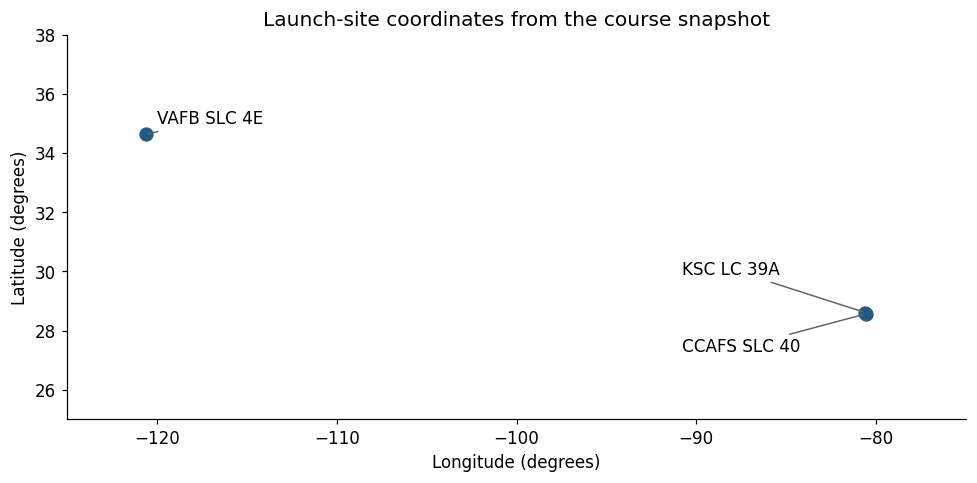

In [3]:
fig, ax = plt.subplots()
ax.scatter(coordinates.longitude, coordinates.latitude, color='#245a81', s=70)
offsets = {'CCAFS SLC 40': (-120,-25), 'KSC LC 39A': (-120,25), 'VAFB SLC 4E': (7,7)}
for row in coordinates.itertuples():
    ax.annotate(row.LaunchSite, (row.longitude,row.latitude), xytext=offsets[row.LaunchSite], textcoords='offset points', arrowprops={'arrowstyle':'-', 'color':'#666666'})
ax.set(xlabel='Longitude (degrees)', ylabel='Latitude (degrees)', title='Launch-site coordinates from the course snapshot', xlim=(-125,-75), ylim=(25,38))
plt.tight_layout(); plt.show()

## Takeaways
Coordinates are historical course source values. No railway, highway, or coastline distance is claimed without a sourced reference geometry and a declared measurement method.